In [ ]:
#Thư viện cần dùng:
import numpy as np
import random
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
# Xây dựng lại game dò mìn cấp beginer:
class MinesweeperAI_Env:
    def __init__(self, rows=8, cols=8, mines=10):
        self.rows = rows
        self.cols = cols
        self.mines = mines
        self.board = np.zeros((rows, cols), dtype=int)
        self.visible = np.zeros((rows, cols), dtype=bool)
        self.game_over = False
        self.win = False
        self.first_click = True

    def _place_mines_and_calc(self, first_r, first_c):
        # 1. Rải mìn ngẫu nhiên nhưng né tọa độ click đầu tiên
        safe_zone = [(r, c) for r in range(max(0, first_r - 1), min(self.rows, first_r + 2))
                     for c in range(max(0, first_c - 1), min(self.cols, first_c + 2))]

        mines_placed = 0
        while mines_placed < self.mines:
          r = random.randint(0, self.rows - 1)
          c = random.randint(0, self.cols - 1)
          if (r, c) not in safe_zone and self.board[r, c] != -1:
                self.board[r, c] = -1
                mines_placed += 1

        # 2. Tính toán các con số (1, 2, 3...) xung quanh mìn
        for r in range(self.rows):
            for c in range(self.cols):
                if self.board[r, c] == -1:
                    continue
                mine_count = 0
                for i in range(max(0, r-1), min(self.rows, r+2)):
                    for j in range(max(0, c-1), min(self.cols, c+2)):
                        if self.board[i, j] == -1:
                            mine_count += 1
                self.board[r, c] = mine_count

    def reveal(self, r, c):
        # Chặn nếu game đã kết thúc hoặc ô này đã mở rồi (chống lặp vô hạn)
        if self.game_over or self.visible[r, c]:
            return

        # Kích hoạt tạo bàn cờ ở cú click đầu tiên
        if self.first_click:
            self._place_mines_and_calc(r, c)
            self.first_click = False

        # Mở ô
        self.visible[r, c] = True

        # Kiểm tra đạp mìn (Thua)
        if self.board[r, c] == -1:
            self.game_over = True
            return

        # Cơ chế Flood fill tự động lan rộng khi chạm vào số 0
        if self.board[r, c] == 0:
            for i in range(max(0, r-1), min(self.rows, r+2)):
                for j in range(max(0, c-1), min(self.cols, c+2)):
                    if not self.visible[i, j]:
                        self.reveal(i, j)

        # Kiểm tra điều kiện Thắng
        if np.sum(~self.visible) == self.mines:
            self.game_over = True
            self.win = True


In [ ]:
#PHẦN 2: MÔ HÌNH AI
from sklearn.linear_model import LogisticRegression

class MinesweeperAI:
    def __init__(self):
        self.model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
        self.X_data = [] # Lưu ma trận 8 ô hàng xóm
        self.y_data = [] # Lưu nhãn: 1 là Bom, 0 là An toàn

    def extract_features(self, game, r, c):
        """Hàm 'mắt nhìn' của AI: Cắt lấy các ô xung quanh ô (r, c)"""
        features = []
        for i in range(r-1, r+2):
            for j in range(c-1, c+2):
                if i == r and j == c:
                    continue # Bỏ qua chính ô đang xét

                # Ngoài biên bàn cờ -> gán -2
                if i < 0 or i >= game.rows or j < 0 or j >= game.cols:
                    features.append(-2)
                # Ô hàng xóm chưa lật -> gán -1
                elif not game.visible[i, j]:
                    features.append(-1)
                # Ô hàng xóm đã lật -> lấy đúng số hiển thị (0, 1, 2...)
                else:
                    features.append(game.board[i, j])
        return features

    def generate_training_data(self, num_games=500):
        """Cho máy tự chơi để thu thập dữ liệu"""
        print(f"🔄 Đang tự động cày {num_games} ván để thu thập Data...")

        for _ in range(num_games):
            game = MinesweeperAI_Env(rows=8, cols=8, mines=10)
            game.reveal(random.randint(0, 7), random.randint(0, 7))

            for _ in range(3):
                if not game.game_over:
                    game.reveal(random.randint(0, 7), random.randint(0, 7))

            for r in range(game.rows):
                for c in range(game.cols):
                    if not game.visible[r, c]:
                        features = self.extract_features(game, r, c)
                        if any(val >= 0 for val in features):
                            self.X_data.append(features)
                            is_mine = 1 if game.board[r, c] == -1 else 0
                            self.y_data.append(is_mine)

    def train_model(self):
        """Bơm Data vào hàm Random forest để huấn luyện"""
        print(f"📊 Đã thu thập được {len(self.X_data)} mẫu dữ liệu thực tế. Bắt đầu Train!")
        X_train, X_test, y_train, y_test = train_test_split(self.X_data, self.y_data, test_size=0.2, random_state=42)

        df = pd.DataFrame(self.X_data, columns=[f'O_xung_quanh_{i+1}' for i in range(8)])
        df['Ket_qua_Thuc_te'] = self.y_data
        df.to_csv('Lich_su_Quet_Min.csv', index=False)
        print("💾 Đã xuất file Lich_su_Quet_Min.csv!")

        # Tối ưu hóa Hyperparameters cho RANDOM FOREST
        param_dist = {
            'n_estimators': [50, 100, 150],       # Số lượng cây quyết định
            'max_depth': [5, 10, 15, None],       # Độ sâu của cây để không học vẹt
            'class_weight': [None, 'balanced']    # Cân bằng dữ liệu mìn/an toàn
        }

        random_search = RandomizedSearchCV(
            RandomForestClassifier(random_state=42), # <--- Thay ở đây!
            param_distributions=param_dist,
            n_iter=10,
            cv=5,
            scoring='f1',
            random_state=42,
            n_jobs=-1
        )
        random_search.fit(X_train, y_train)
        self.model = random_search.best_estimator_
        print(f"✨ Đã tìm ra cấu hình Rừng xịn nhất: {random_search.best_params_}")

        # Khớp lại mô hình xuất sắc nhất trên tập train
        self.model.fit(X_train, y_train)

        # Đánh giá AI trên tập test
        predictions = self.model.predict(X_test)
        y_scores = self.model.predict_proba(X_test)[:, 1]

        precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
        pr_auc = auc(recall, precision)

        print("\n📊 BẢNG PHÂN TÍCH CHI TIẾT (Precision - Recall / Accuracy):")
        print(classification_report(y_test, predictions, target_names=['An Toàn (0)', 'Mìn (1)']))

        plt.figure(figsize=(8, 6))
        plt.plot(recall, precision, color='darkorange', lw=2, label=f'PR Curve (AUC = {pr_auc:.2f})')
        plt.xlabel('Recall (Khả năng không bỏ lọt mìn)')
        plt.ylabel('Precision (Độ tin cậy khi phán đoán)')
        plt.title('Biểu đồ Precision-Recall (PR-AUC) đánh giá mô hình Dò Mìn')
        plt.legend(loc="lower left")
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

    def choose_next_move(self, game, known_mines):
        """Bộ não trung tâm: Tự động cập nhật cờ và trả về (tọa_độ, loại_nước_đi, rủi_ro)"""
        def get_unopened(r, c):
            return [(i, j) for i in range(max(0, r-1), min(game.rows, r+2))
                           for j in range(max(0, c-1), min(game.cols, c+2))
                           if not game.visible[i, j]]

        # 1. LUẬT 1: CẮM CỜ & TÌM Ô AN TOÀN 100%
        for r in range(game.rows):
            for c in range(game.cols):
                if game.visible[r, c] and game.board[r, c] > 0:
                    unopened = get_unopened(r, c)
                    if len(unopened) == game.board[r, c]:
                        known_mines.update(unopened)

                    unflagged = [pos for pos in unopened if pos not in known_mines]
                    if (len(unopened) - len(unflagged)) == game.board[r, c] and unflagged:
                        return unflagged[0], "SAFE", 0.0

        # 2. LUẬT 2: DÙNG MÔ HÌNH AI DỰ ĐOÁN
        best_move, fallback_move = None, None
        lowest_prob = 1.0

        for r in range(game.rows):
            for c in range(game.cols):
                if not game.visible[r, c] and (r, c) not in known_mines:
                    if not fallback_move:
                        fallback_move = (r, c)

                    features = self.extract_features(game, r, c)
                    if any(val >= 0 for val in features):
                        prob = self.model.predict_proba([features])[0][1]
                        if prob < lowest_prob:
                            lowest_prob, best_move = prob, (r, c)

        if best_move:
            return best_move, "AI", lowest_prob
        return fallback_move, "BLIND", 0.50

In [ ]:
# 1. Khởi tạo đối tượng AI
ai = MinesweeperAI()




🔄 Đang tự động cày 2000 ván để thu thập Data...
📊 Đã thu thập được 33330 mẫu dữ liệu thực tế. Bắt đầu Train!
💾 Đã xuất file Lich_su_Quet_Min.csv!
✨ Đã tìm ra cấu hình Rừng xịn nhất: {'n_estimators': 100, 'max_depth': 10, 'class_weight': 'balanced'}

📊 BẢNG PHÂN TÍCH CHI TIẾT (Precision - Recall / Accuracy):
              precision    recall  f1-score   support

 An Toàn (0)       0.80      0.84      0.82      3901
     Mìn (1)       0.76      0.71      0.73      2765

    accuracy                           0.78      6666
   macro avg       0.78      0.77      0.78      6666
weighted avg       0.78      0.78      0.78      6666



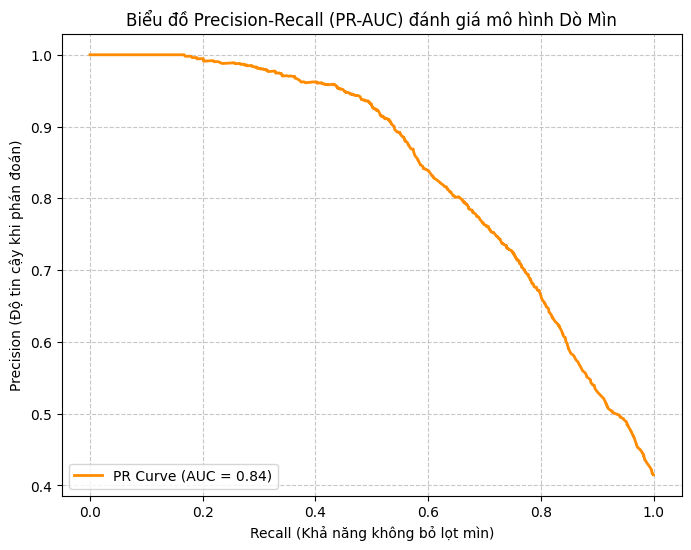

Đã lưu file não AI thành công!


In [ ]:
# 2. Thu thập dữ liệu từ 2000 ván game (bạn có thể tăng số lượng nếu muốn AI học nhiều hơn)
ai.generate_training_data(num_games=2000)

# 3. Huấn luyện mô hình và in ra độ chính xác
ai.train_model()
import joblib
joblib.dump(ai.model, 'do_min_random_forest.pkl')
print("Đã lưu file não AI thành công!")

In [ ]:
import joblib
from sklearn.metrics import classification_report

# 1. Khởi tạo con AI mới (hoặc gọi lại class cũ)
ai_validator = MinesweeperAI()

# 2. NẠP NÃO ĐÃ LƯU TỪ HÔM QUA VÀO MÔ HÌNH
ai_validator.model = joblib.load('do_min_random_forest.pkl')
print("🧠 Đã nạp thành công bộ não AI từ file .pkl!")

# 3. CHẠY VALIDATION TỰ ĐỘNG (Ví dụ cho AI chơi thử 100 ván liên tục)
wins = 0
total_games = 100

for g in range(total_games):
    game = MinesweeperAI_Env(rows=8, cols=8, mines=10)
    game.reveal(game.rows // 2, game.cols // 2)
    known_mines = set()

    while not game.game_over:
        # Chỉ cần gọi đúng 1 dòng này!
        move, move_type, prob = ai_validator.choose_next_move(game, known_mines)
        if not move:
            break
        game.reveal(move[0], move[1])

    if game.win:
        wins += 1


# 4. IN BÁO CÁO KẾT QUẢ VALIDATION
win_rate = (wins / total_games) * 100
print("\n" + "="*40)
print(f"📊 KẾT QUẢ VALIDATION TRÊN {total_games} VÁN:")
print(f"🏆 Số ván thắng: {wins}")
print(f"💥 Số ván thua: {total_games - wins}")
print(f"🎯 Tỷ lệ thắng thực tế: {(wins/total_games)*100:.2f}%")
print("="*40)

🧠 Đã nạp thành công bộ não AI từ file .pkl!

📊 KẾT QUẢ VALIDATION TRÊN 100 VÁN:
🏆 Số ván thắng: 63
💥 Số ván thua: 37
🎯 Tỷ lệ thắng thực tế: 63.00%


In [ ]:
def watch_smart_ai_play(bot):
    print("🤖 AI bắt đầu biểu diễn...")
    game = MinesweeperAI_Env(rows=8, cols=8, mines=10)
    game.reveal(game.rows // 2, game.cols // 2)
    print("👉 Bước 1: Khai cuộc tại (3, 3)")

    steps = 1
    known_mines = set()

    while not game.game_over:
        # Gọi não AI ra quyết định trong 1 nốt nhạc
        move, move_type, prob = bot.choose_next_move(game, known_mines)
        if not move:
            break

        r, c = move
        steps += 1
        if move_type == "SAFE":
            print(f"👉 Bước {steps}: Mở ({r}, {c}) - [LUẬT LOGIC: An toàn 100%]")
        else:
            print(f"👉 Bước {steps}: Mở ({r}, {c}) - [AI DỰ ĐOÁN - Rủi ro: {prob*100:.1f}%]")

        game.reveal(r, c)

    # In bàn cờ cuối game
    print("\n" + "="*40)
    print(f"🏆 PHÁ ĐẢO SAU {steps} BƯỚC!" if game.win else f"💥 HY SINH TẠI BƯỚC {steps}!")
    for r in range(game.rows):
        print(" ".join([
            ("🚩" if (r, c) in known_mines else "■ ") if not game.visible[r, c]
            else ("💣" if game.board[r, c] == -1 else f"{game.board[r, c]} ")
            for c in range(game.cols)
        ]))
watch_smart_ai_play(ai)

🤖 AI bắt đầu biểu diễn...
👉 Bước 1: Khai cuộc tại (3, 3)
👉 Bước 2: Mở (6, 5) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 3: Mở (1, 3) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 4: Mở (0, 2) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 5: Mở (2, 1) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 6: Mở (2, 2) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 7: Mở (3, 1) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 8: Mở (3, 2) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 9: Mở (1, 7) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 10: Mở (0, 6) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 11: Mở (0, 7) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 12: Mở (5, 2) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 13: Mở (2, 0) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 14: Mở (3, 0) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 15: Mở (4, 0) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 16: Mở (0, 0) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 17: Mở (5, 0) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 18: Mở (5, 1) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 19: Mở (6, 0) - [LUẬT LOGIC: An toàn 100%]
👉 Bước 20: Mở (6, 2) - [LUẬT LOGIC: An toàn 100%]
👉